## [LAB-07] 추론통계

### 04-4_이원분산분석의 사후검정

### #01 준비작업

#### 1. 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *
from pandas import DataFrame
import numpy as np

# 사후검정을 위한 라이브러리
from pingouin import pairwise_tukey, pairwise_gameshowell

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: 0.5.30


#### 2. 데이터 가져오기

In [2]:
origin = load_data('sunlight_watering_growth')
origin.head()

📚 식물의 씨앗을 심고 햇빛 노출과 물 주기를 다른 조건으로 하여 두 달 동안 자라게 한 후 각 식물의 높이를 인치 단위로 기록한 데이터 (출처: 방송통신대학교 통계학개론)


,water,sun,height
0,daily,low,4.900
1,daily,low,7.900
2,daily,low,3.900
3,daily,low,5.100
4,daily,low,5.200


### #02 분산분석의 가정 확인

#### 1. 모든 명목형의 조합에 따른 종속변수 재배치

In [3]:
data = origin.copy()
xname = ['water', 'sun']        # 명목형 변수의 이름
yname = 'height'                # 연속형 변수의 이름

# 두 명목형 변수의 모든 조합별로 연속형 변수 값을 별도의 컬럼으로 분리한다.
groups = {}
for i in data[xname[0]].unique():
    for j in data[xname[1]].unique():
        # 명목형 변수의 조합 조건에 맞는 데이터를 추출한다.
        filtered_data = data[(data[xname[0]] == i) & (data[xname[1]] == j)][yname]
        groups["{0}, {1}".format(i, j)] = filtered_data.reset_index(drop=True)

# 조합별 표본 크기가 다를 수 있으므로 DataFrame으로 결합하면 짧은 쪽은 NaN으로 채워진다.
# test_assumptions는 내부적으로 결측치를 제거한 뒤 검정하므로 문제되지 않는다.
group_df = DataFrame(groups)
group_df.head()

,"daily, low","daily, med","daily, high","weekly, low","weekly, med","weekly, high"
0,4.900,5.600,8.600,3.900,4.800,5.200
1,7.900,6.500,8.800,3.300,3.600,4.700
2,3.900,6.500,9.200,4.300,5.700,6.900
3,5.100,6.000,7.100,3.300,4.100,5.100
4,5.200,7.100,8.600,4.500,4.600,7.100


#### 2. 정규성에 따른 등분산성 검정

In [4]:
# 정규성(normaltest)과 등분산성(Bartlett/Levene) 가정을 일괄 검정한다.
rdf = my_stats.test_assumptions(group_df)
display(rdf)

# 등분산성 충족 여부 (이후 사후검정 방법 선택에 사용)
equal_var = bool(rdf.loc[rdf['test'] == 'equal_var', 'result'].iloc[0])
equal_var

,test,statistic,p-value,result
field,,,,
"daily, low",normaltest,1.462,0.482,True
"daily, med",normaltest,0.867,0.648,True
"daily, high",normaltest,0.802,0.670,True
"weekly, low",normaltest,0.074,0.964,True
"weekly, med",normaltest,0.161,0.923,True
"weekly, high",normaltest,0.053,0.974,True
Bartlett,equal_var,4.488,0.481,True


True

### #03 사후검정 (Post-hoc)

#### 1. water와 sun의 조합이름 컬럼 생성

In [5]:
ph = origin.copy()
ph['group'] = ph['water'] + ', ' + ph['sun']
ph.head()

,water,sun,height,group
0,daily,low,4.900,"daily, low"
1,daily,low,7.900,"daily, low"
2,daily,low,3.900,"daily, low"
3,daily,low,5.100,"daily, low"
4,daily,low,5.200,"daily, low"


#### 2. 등분산성 가정에 따른 사후검정 방법 분기

In [6]:
if equal_var:
    posthoc_name = "Tukey HSD"
    posthoc = pairwise_tukey(data=ph, dv=yname, between='group')
    # 유의수준 컬럼명 변경
    posthoc.rename(columns={"p_tukey": "pval"}, inplace=True)
else:
    posthoc_name = "Games-Howell"
    posthoc = pairwise_gameshowell(data=ph, dv=yname, between='group')

# 어떤 사후검정을 사용했는지 식별용 컬럼 추가
posthoc.insert(0, 'test', posthoc_name)

posthoc

,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges
0,Tukey HSD,"daily, high","daily, low",7.980,5.465,2.515,0.307,8.199,0.000,2.165
1,Tukey HSD,"daily, high","daily, med",7.980,6.395,1.585,0.307,5.167,0.000,1.488
2,Tukey HSD,"daily, high","weekly, high",7.980,5.485,2.495,0.307,8.134,0.000,2.288
3,Tukey HSD,"daily, high","weekly, low",7.980,3.455,4.525,0.307,14.752,0.000,4.216
4,Tukey HSD,"daily, high","weekly, med",7.980,4.830,3.150,0.307,10.269,0.000,2.831
5,Tukey HSD,"daily, low","daily, med",5.465,6.395,-0.930,0.307,-3.032,0.035,-0.969
6,Tukey HSD,"daily, low","weekly, high",5.465,5.485,-0.020,0.307,-0.065,1.000,-0.020
7,Tukey HSD,"daily, low","weekly, low",5.465,3.455,2.010,0.307,6.553,0.000,2.074
8,Tukey HSD,"daily, low","weekly, med",5.465,4.830,0.635,0.307,2.070,0.310,0.627
9,Tukey HSD,"daily, med","weekly, high",6.395,5.485,0.910,0.307,2.967,0.042,1.043


#### 3. 출력 결과 가공하기

In [7]:
# 사후검정 결과에 유의성 판정 컬럼 추가 (p < 0.05 이면 효과 존재)
posthoc["significant"] = posthoc["pval"] < 0.05

# 효과크기 해석 (≥ 0.8 큼, ≥ 0.5 중간, ≥ 0.2 작음)
abs_hedges = posthoc["hedges"].abs()
conditions = [abs_hedges >= 0.8, abs_hedges >= 0.5, abs_hedges >= 0.2]
posthoc["effect_size"] = np.select(conditions, ["Large", "Medium", "Small"], default="Negligible")

# 그룹 이름순으로 정렬
posthoc.sort_values(['A', 'B'], inplace=True)

# 사후검정 결과를 시각적으로 강조하기 위해 p-value 컬럼에 색상 그라데이션 적용
style = posthoc.style.background_gradient(cmap='Reds', subset=['pval'])

style

,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,"daily, high","daily, low",7.980000,5.465000,2.515000,0.306743,8.199049,0.000000,2.165102,True,Large
1,Tukey HSD,"daily, high","daily, med",7.980000,6.395000,1.585001,0.306743,5.167195,0.000015,1.488325,True,Large
2,Tukey HSD,"daily, high","weekly, high",7.980000,5.485000,2.495001,0.306743,8.133850,0.000000,2.288309,True,Large
3,Tukey HSD,"daily, high","weekly, low",7.980000,3.455000,4.525001,0.306743,14.751768,0.000000,4.215536,True,Large
4,Tukey HSD,"daily, high","weekly, med",7.980000,4.830000,3.150001,0.306743,10.269187,0.000000,2.831045,True,Large
5,Tukey HSD,"daily, low","daily, med",5.465000,6.395000,-0.930000,0.306743,-3.031854,0.034790,-0.968866,True,Large
6,Tukey HSD,"daily, low","weekly, high",5.465000,5.485000,-0.020000,0.306743,-0.065200,1.000000,-0.020244,False,Negligible
7,Tukey HSD,"daily, low","weekly, low",5.465000,3.455000,2.010000,0.306743,6.552719,0.000000,2.073754,True,Large
8,Tukey HSD,"daily, low","weekly, med",5.465000,4.830000,0.635000,0.306743,2.070138,0.310347,0.627126,False,Medium
9,Tukey HSD,"daily, med","weekly, high",6.395000,5.485000,0.910000,0.306743,2.966655,0.041646,1.043256,True,Large


> - `daily, high`(평균 7.98 inch)가 가장 크게 자랐고, `weekly, low`(평균 3.46 inch)가 가장 작았다.
> - 두 집단의 차이(4.53 inch)는 통계적으로 유의하고(p < 0.001) 집단간의 효과 크기도 매우 크다.
>   - 가장 빠른 성장을 원하면 `daily + high` 조합이 최적
> 
> - 15쌍 중 12쌍이 통계적으로 유의(p < 0.05)하며, 대부분 효과크기가 Large이다. 즉 대부분의 조합 간 식물 높이 차이가 뚜렷하다.
>   - 식물 높이를 통계적으로 구분할 수 없는 조합은 총 3쌍이다.
> 
> - 물을 매일 주고 햇빛에 적게 노출시킨 집단(daily, low)과 물을 1주일에 한번 주고 햇빛에 중간 혹은 많이 노출시킨 집단(weekly, hight / weekly, med)간의 평균이 유사하다.
>   - 즉 물을 적게 주더라도 햇빛을 충분히 받으면, 물을 매일 주되 햇빛이 부족한 환경과 같은 수준의 성장을 달성할 수 있다.
> - 한 요인의 부족분을 다른 요인이 메워줄 수 있음을 보여준다. (가산적 보상)
> - 자원(물·일조 환경)이 제약될 경우 위 보상 관계를 활용해 조건을 결정할 수 있다.

#### 4. 사후검정 결과 요약

In [8]:
print(f"비교한 조합 쌍: {len(posthoc)}개")
print(f"유의한 쌍: {int(posthoc["significant"].sum())}개")

big = posthoc.loc[posthoc["diff"].abs().idxmax()]
print(f"평균 차이가 가장 큰 쌍: ({big["A"]}) vs ({big["B"]}) "
      f"→ 차이 {abs(big["diff"]):.3f}, 효과크기 {big["effect_size"]}, p-value {big["pval"]:.3f}")

sm = posthoc.loc[posthoc["diff"].abs().idxmin()]
print(f"평균 차이가 가장 작은 쌍: ({sm["A"]}) vs ({sm["B"]}) "
      f"→ 차이 {abs(sm["diff"]):.3f}, 효과크기 {sm["effect_size"]}, p-value {sm["pval"]:.3f}")

비교한 조합 쌍: 15개
유의한 쌍: 12개
평균 차이가 가장 큰 쌍: (daily, high) vs (weekly, low) → 차이 4.525, 효과크기 Large, p-value 0.000
평균 차이가 가장 작은 쌍: (daily, low) vs (weekly, high) → 차이 0.020, 효과크기 Negligible, p-value 1.000


#### 5. 같은 관수빈도 안에서의 햇빛량 비교

In [9]:
for p in ['daily', 'weekly']:
    sub = (posthoc[posthoc['A'].str.startswith(p) &
                   posthoc['B'].str.startswith(p)])

    # 유의한 쌍(significant == True)만 추출
    sig = sub[sub['significant']]

    print(f"\n[{p}]  {len(sub)}쌍 중 유의한 쌍이 {len(sig)}개")
    print(sig[['A', 'B', 'diff', 'pval', 'significant']].to_string(index=False))


[daily]  3쌍 중 유의한 쌍이 3개
          A          B   diff  pval  significant
daily, high daily, low  2.515 0.000         True
daily, high daily, med  1.585 0.000         True
 daily, low daily, med -0.930 0.035         True

[weekly]  3쌍 중 유의한 쌍이 2개
           A           B   diff  pval  significant
weekly, high weekly, low  2.030 0.000         True
 weekly, low weekly, med -1.375 0.000         True


### #04 사후검정 시각화 (박스플롯)

#### 1. 그래프 정렬 순서 생성

- 사후검정은 집단간 평균에 유의미한 차이가 있는지를 검정하는 분석기법이므로 데이터의 분포와 평균을 비교할 수 있는 상자 그림으로 시각화 하는 것이 좋다.
- 다만, 유의수준까지 함께 표시할 경우 그래프가 지나치게 복잡해 지므로 필요한 부분만 ppt 등으로 따로 표시하는 방법을 권장한다.

In [10]:
order = (ph[['group', 'height']].groupby('group').mean()
         .sort_values('height', ascending=False).index.tolist())
order

['daily, high',
 'daily, med',
 'weekly, high',
 'daily, low',
 'weekly, med',
 'weekly, low']

#### 2. 상자그림 시각화

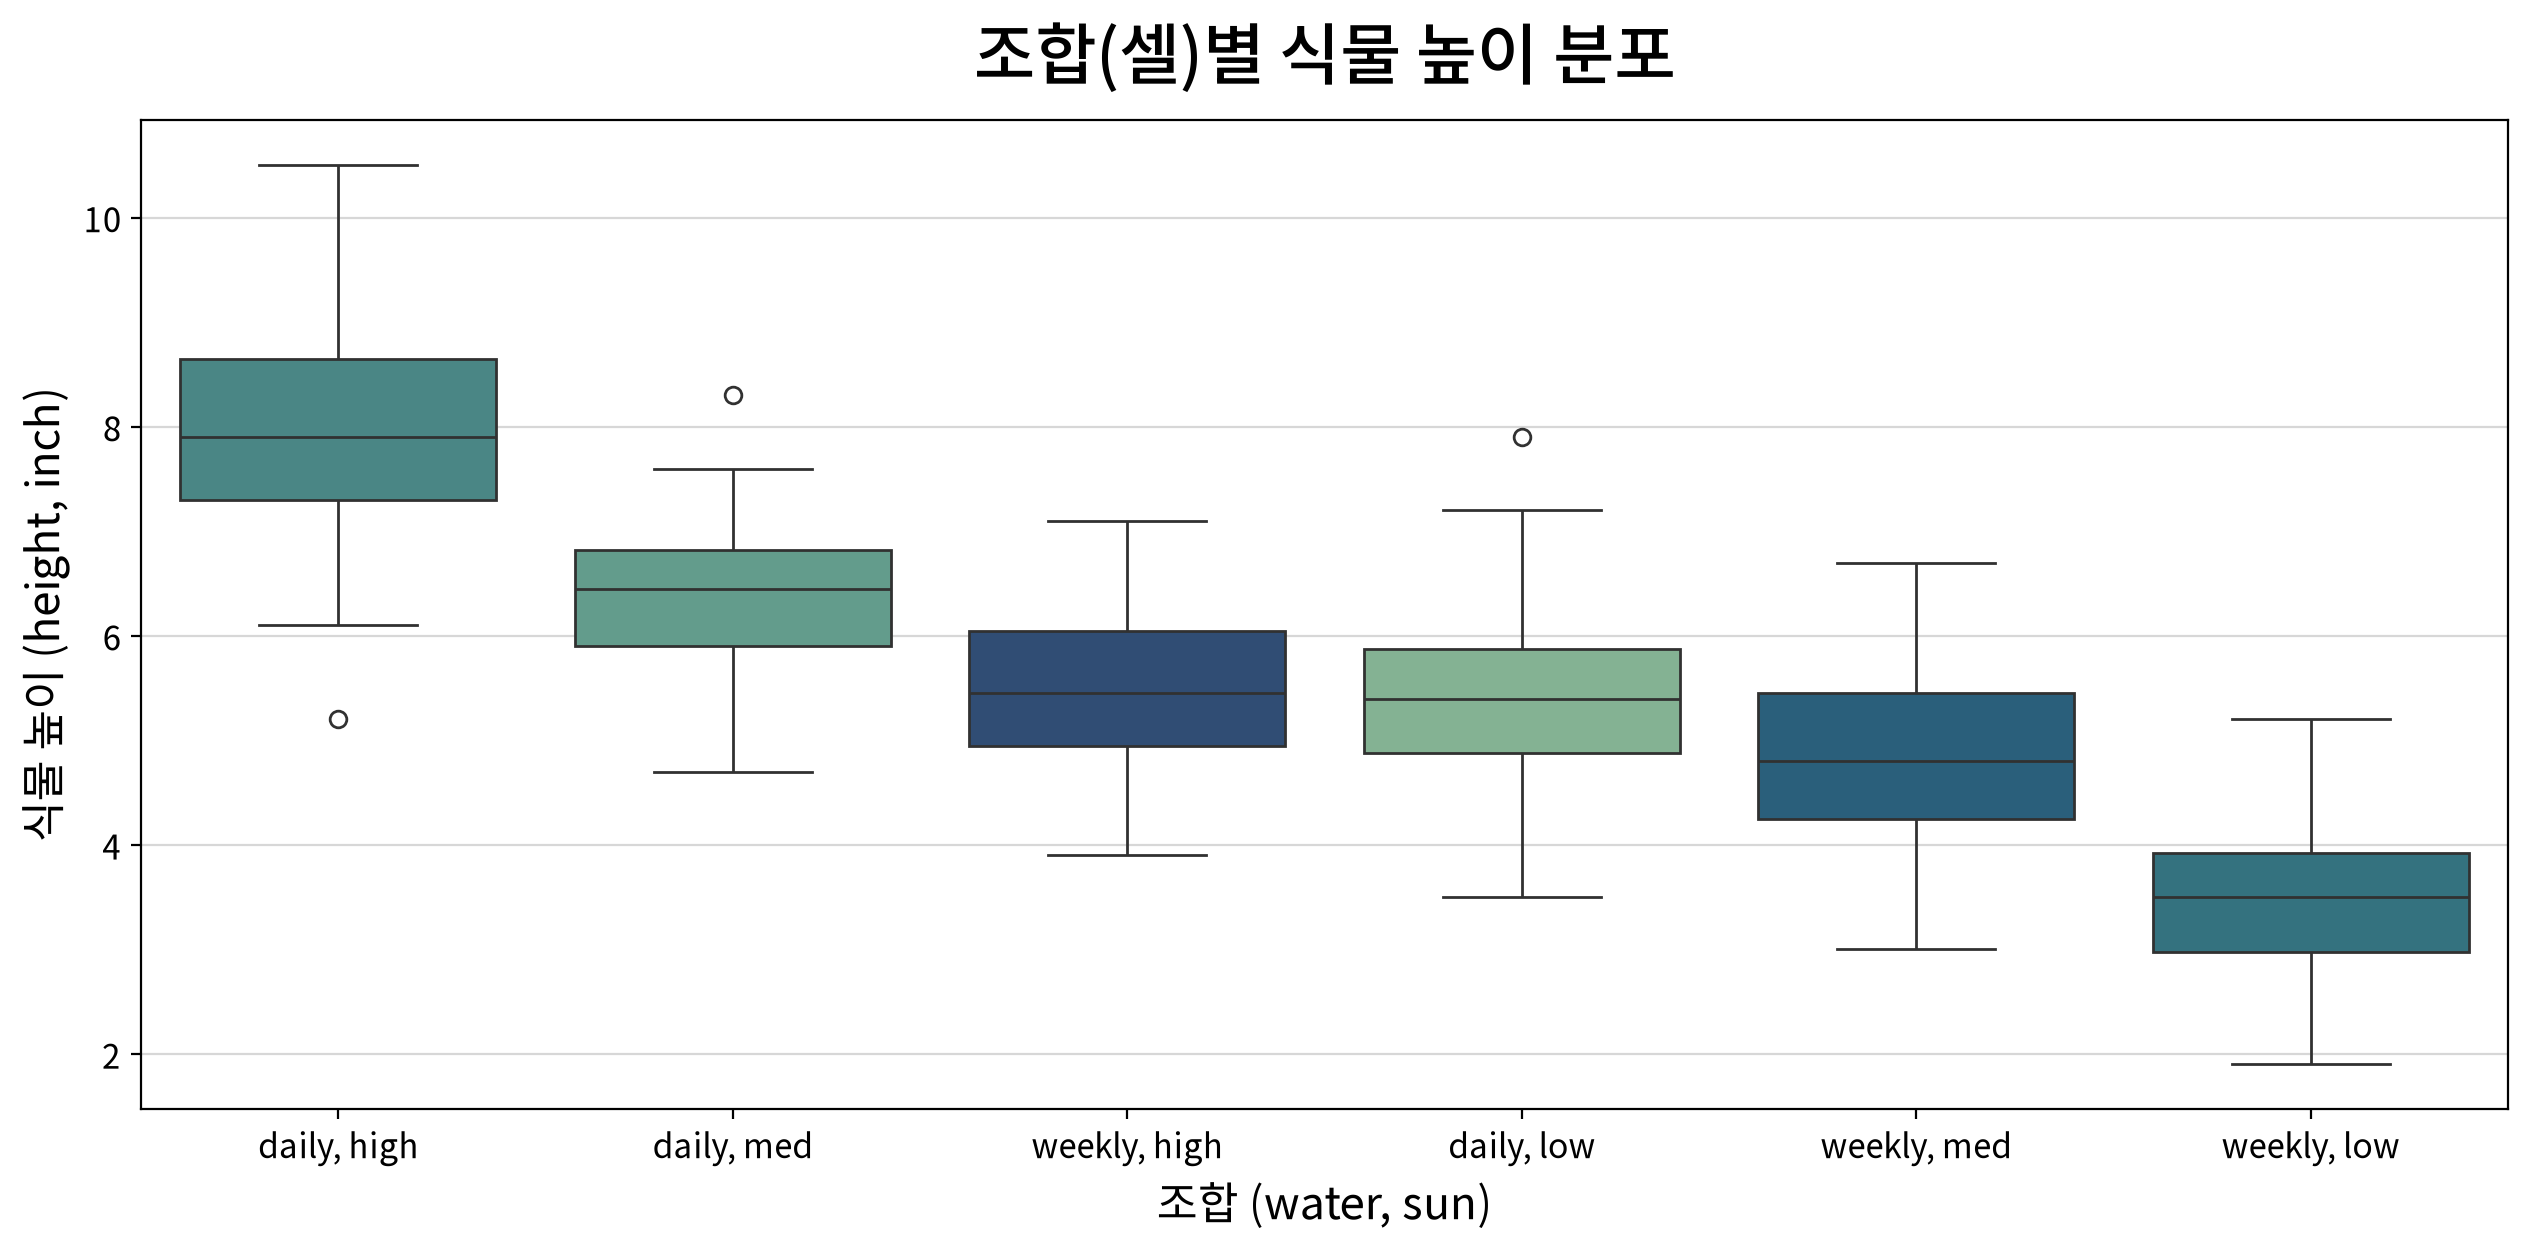

In [11]:
my_plot.boxplot(data=ph, x='group', y='height', order=order, palette='crest',
                title='조합(셀)별 식물 높이 분포',
                xlabel='조합 (water, sun)',
                ylabel='식물 높이 (height, inch)')

> 인사이트
> - 유의미한 차이가 없는 비교군
>   - daily, low - weekly, hight
>   - daily, low - weekly, med
>   - weekly, hight - weekly, med

### #05 모듈화 기능 확인

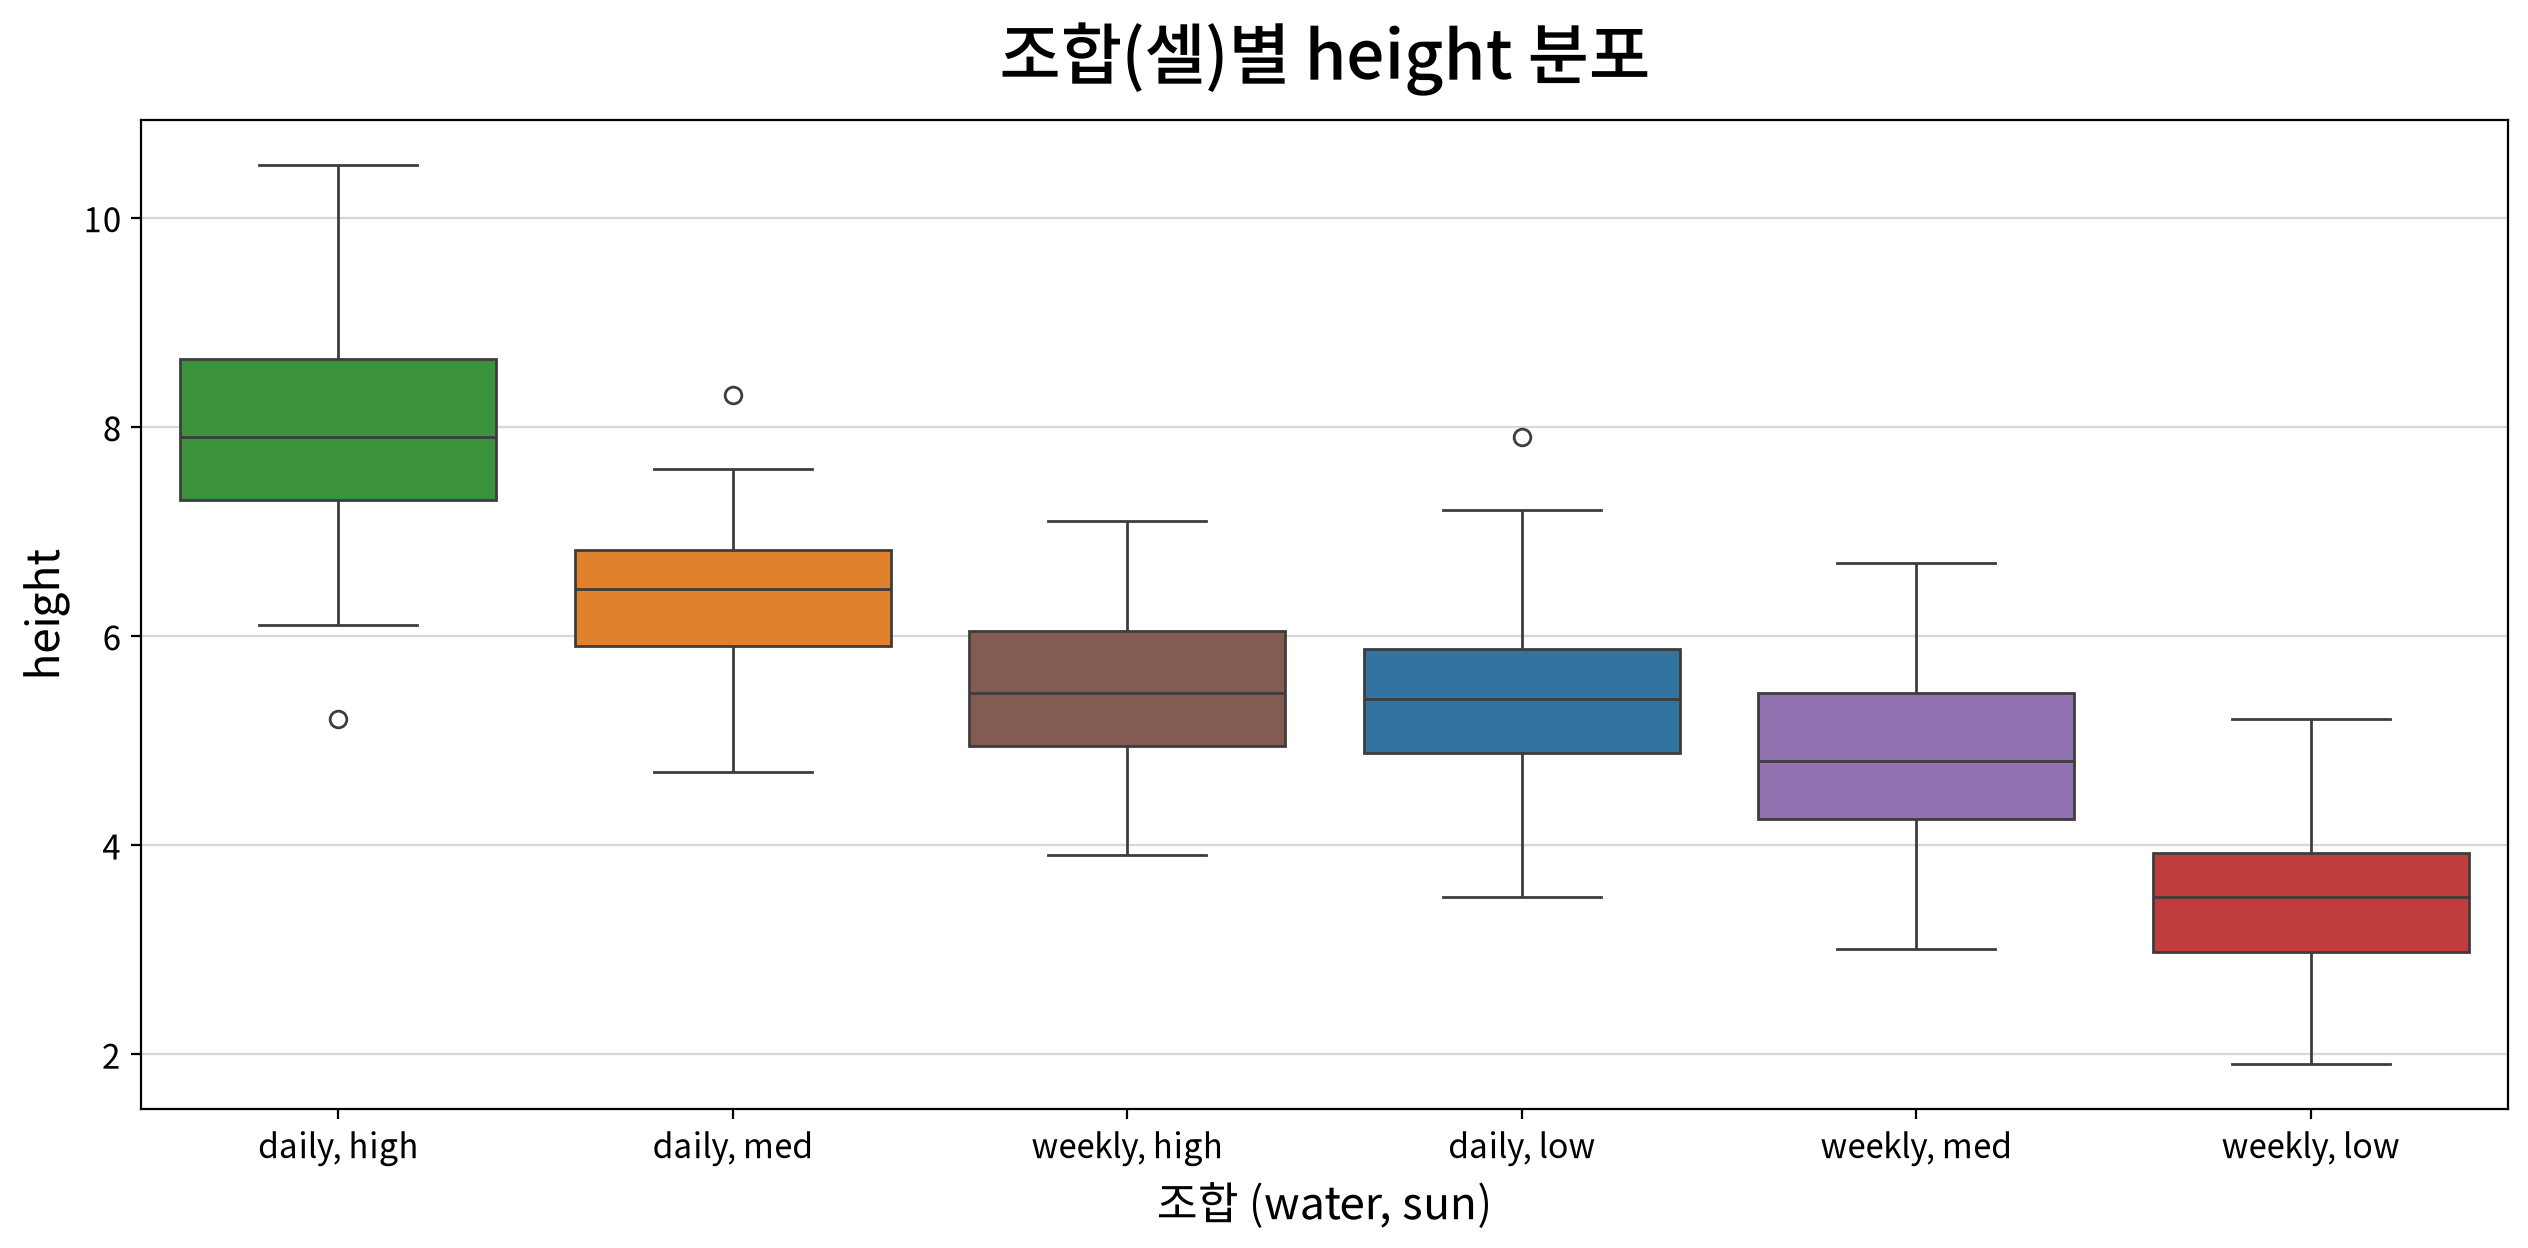

비교한 조합 쌍: 15개
유의한 쌍: 12개
평균 차이가 가장 큰 쌍: (daily, high) vs (weekly, low) → 차이 4.525, 효과크기 Large, p-value 0.000
평균 차이가 가장 작은 쌍: (daily, low) vs (weekly, high) → 차이 0.020, 효과크기 Negligible, p-value 1.000

[daily] 3쌍 중 유의한 쌍: 3개
          A          B   diff  pval  significant
daily, high daily, low  2.515 0.000         True
daily, high daily, med  1.585 0.000         True
 daily, low daily, med -0.930 0.035         True

[weekly] 3쌍 중 유의한 쌍: 2개
           A           B   diff  pval  significant
weekly, high weekly, low  2.030 0.000         True
 weekly, low weekly, med -1.375 0.000         True


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,"daily, high","daily, low",7.980,5.465,2.515,0.307,8.199,0.000,2.165,True,Large
1,Tukey HSD,"daily, high","daily, med",7.980,6.395,1.585,0.307,5.167,0.000,1.488,True,Large
2,Tukey HSD,"daily, high","weekly, high",7.980,5.485,2.495,0.307,8.134,0.000,2.288,True,Large
3,Tukey HSD,"daily, high","weekly, low",7.980,3.455,4.525,0.307,14.752,0.000,4.216,True,Large
4,Tukey HSD,"daily, high","weekly, med",7.980,4.830,3.150,0.307,10.269,0.000,2.831,True,Large
5,Tukey HSD,"daily, low","daily, med",5.465,6.395,-0.930,0.307,-3.032,0.035,-0.969,True,Large
6,Tukey HSD,"daily, low","weekly, high",5.465,5.485,-0.020,0.307,-0.065,1.000,-0.020,False,Negligible
7,Tukey HSD,"daily, low","weekly, low",5.465,3.455,2.010,0.307,6.553,0.000,2.074,True,Large
8,Tukey HSD,"daily, low","weekly, med",5.465,4.830,0.635,0.307,2.070,0.310,0.627,False,Medium
9,Tukey HSD,"daily, med","weekly, high",6.395,5.485,0.910,0.307,2.967,0.042,1.043,True,Large


In [12]:
my_stats.posthoc_twoway(origin, y='height',
                        between=['water', 'sun'], palette='tab10')

---

## 연습문제

#### 문제 1 — 신입교사의 교육방법 채택 고민

- 당신은 한울고등학교의 연구교사입니다.
    - 지난 시간 이원분산분석으로 확인한 결과, 교육방법도 과목도 그 맞물림도 유의수준 5%에서는 유의하지 않았습니다. 당신은 "표본을 늘려 다시 검정해 보자"고 보고했습니다.
    - 그러자 교장 선생님이 조합별 평균표를 짚으며 되묻습니다.
        - "평균만 보면 2번 방법으로 배운 국어(81.4점)가 1번 방법으로 배운 국어(74.5점)보다 7점 가까이 높잖아요. 전체를 뭉뚱그리지 말고, 네 조합을 짝지어 하나씩 비교하면 다른 결론이 나오지 않겠습니까?"
    - 네 개의 조합(교육방법 × 과목)을 서로 짝지어 비교하는 사후검정으로 교장 선생님의 반문에 답하세요.

- 문제

1. 교장 선생님의 요구대로 네 개의 조합을 서로 짝지어 비교했습니다. 사후검정이 비교한 조합 쌍은 모두 몇 개인가요?
2. 교장 선생님이 지목한 것처럼, 평균 점수 차이가 가장 큰 쌍은 1번-국어와 2번-국어의 비교였습니다. 이 두 조합의 평균 차이는 몇 점인가요? (소수 셋째 자리, 부호 없이)
3. 그렇다면 이 6개의 쌍 중에서 유의수준 5%에서 통계적으로 유의한 차이를 보인 쌍은 몇 개인가요?
4. 유의한 쌍은 없었지만 효과크기까지 무시할 수준은 아니었습니다. 6개의 쌍 중 효과크기가 Medium으로 판정된 쌍은 몇 개인가요?
5. 교장 선생님이 콕 집어 물은 1번-국어 대 2번-국어 쌍은, 6쌍 중 평균 차이가 가장 크고 유의확률도 가장 작았습니다. 그 유의확률은 얼마인가요? (소수 셋째 자리)

In [13]:
# 라이브러리 불러오기
from pandas import melt

In [14]:
# 데이터 불러오기
df1 = load_data('edu')
df1.head()

📚 두 가지 교육방법을 비교하기 위하여 능력이 비슷한 고등학교 학생 22명을 추출하고, 11명씩 두 집단으로 나누어 한 학기 동안 각각의 교육방법으로 교육시킨 후 치른 학기말 시험 성적을 조사한 자료 (출처: 방송통신대학교 통계학 개론)


,교육방법,국어,영어
0,1,65,82
1,1,87,79
2,1,73,85
3,1,79,60
4,1,81,65


In [16]:
# 데이터 재배치
mdf1 = melt(df1, id_vars=['교육방법'], value_vars=['국어', '영어'],
            var_name='과목', value_name='점수')
mdf1.head()

,교육방법,과목,점수
0,1,국어,65
1,1,국어,87
2,1,국어,73
3,1,국어,79
4,1,국어,81


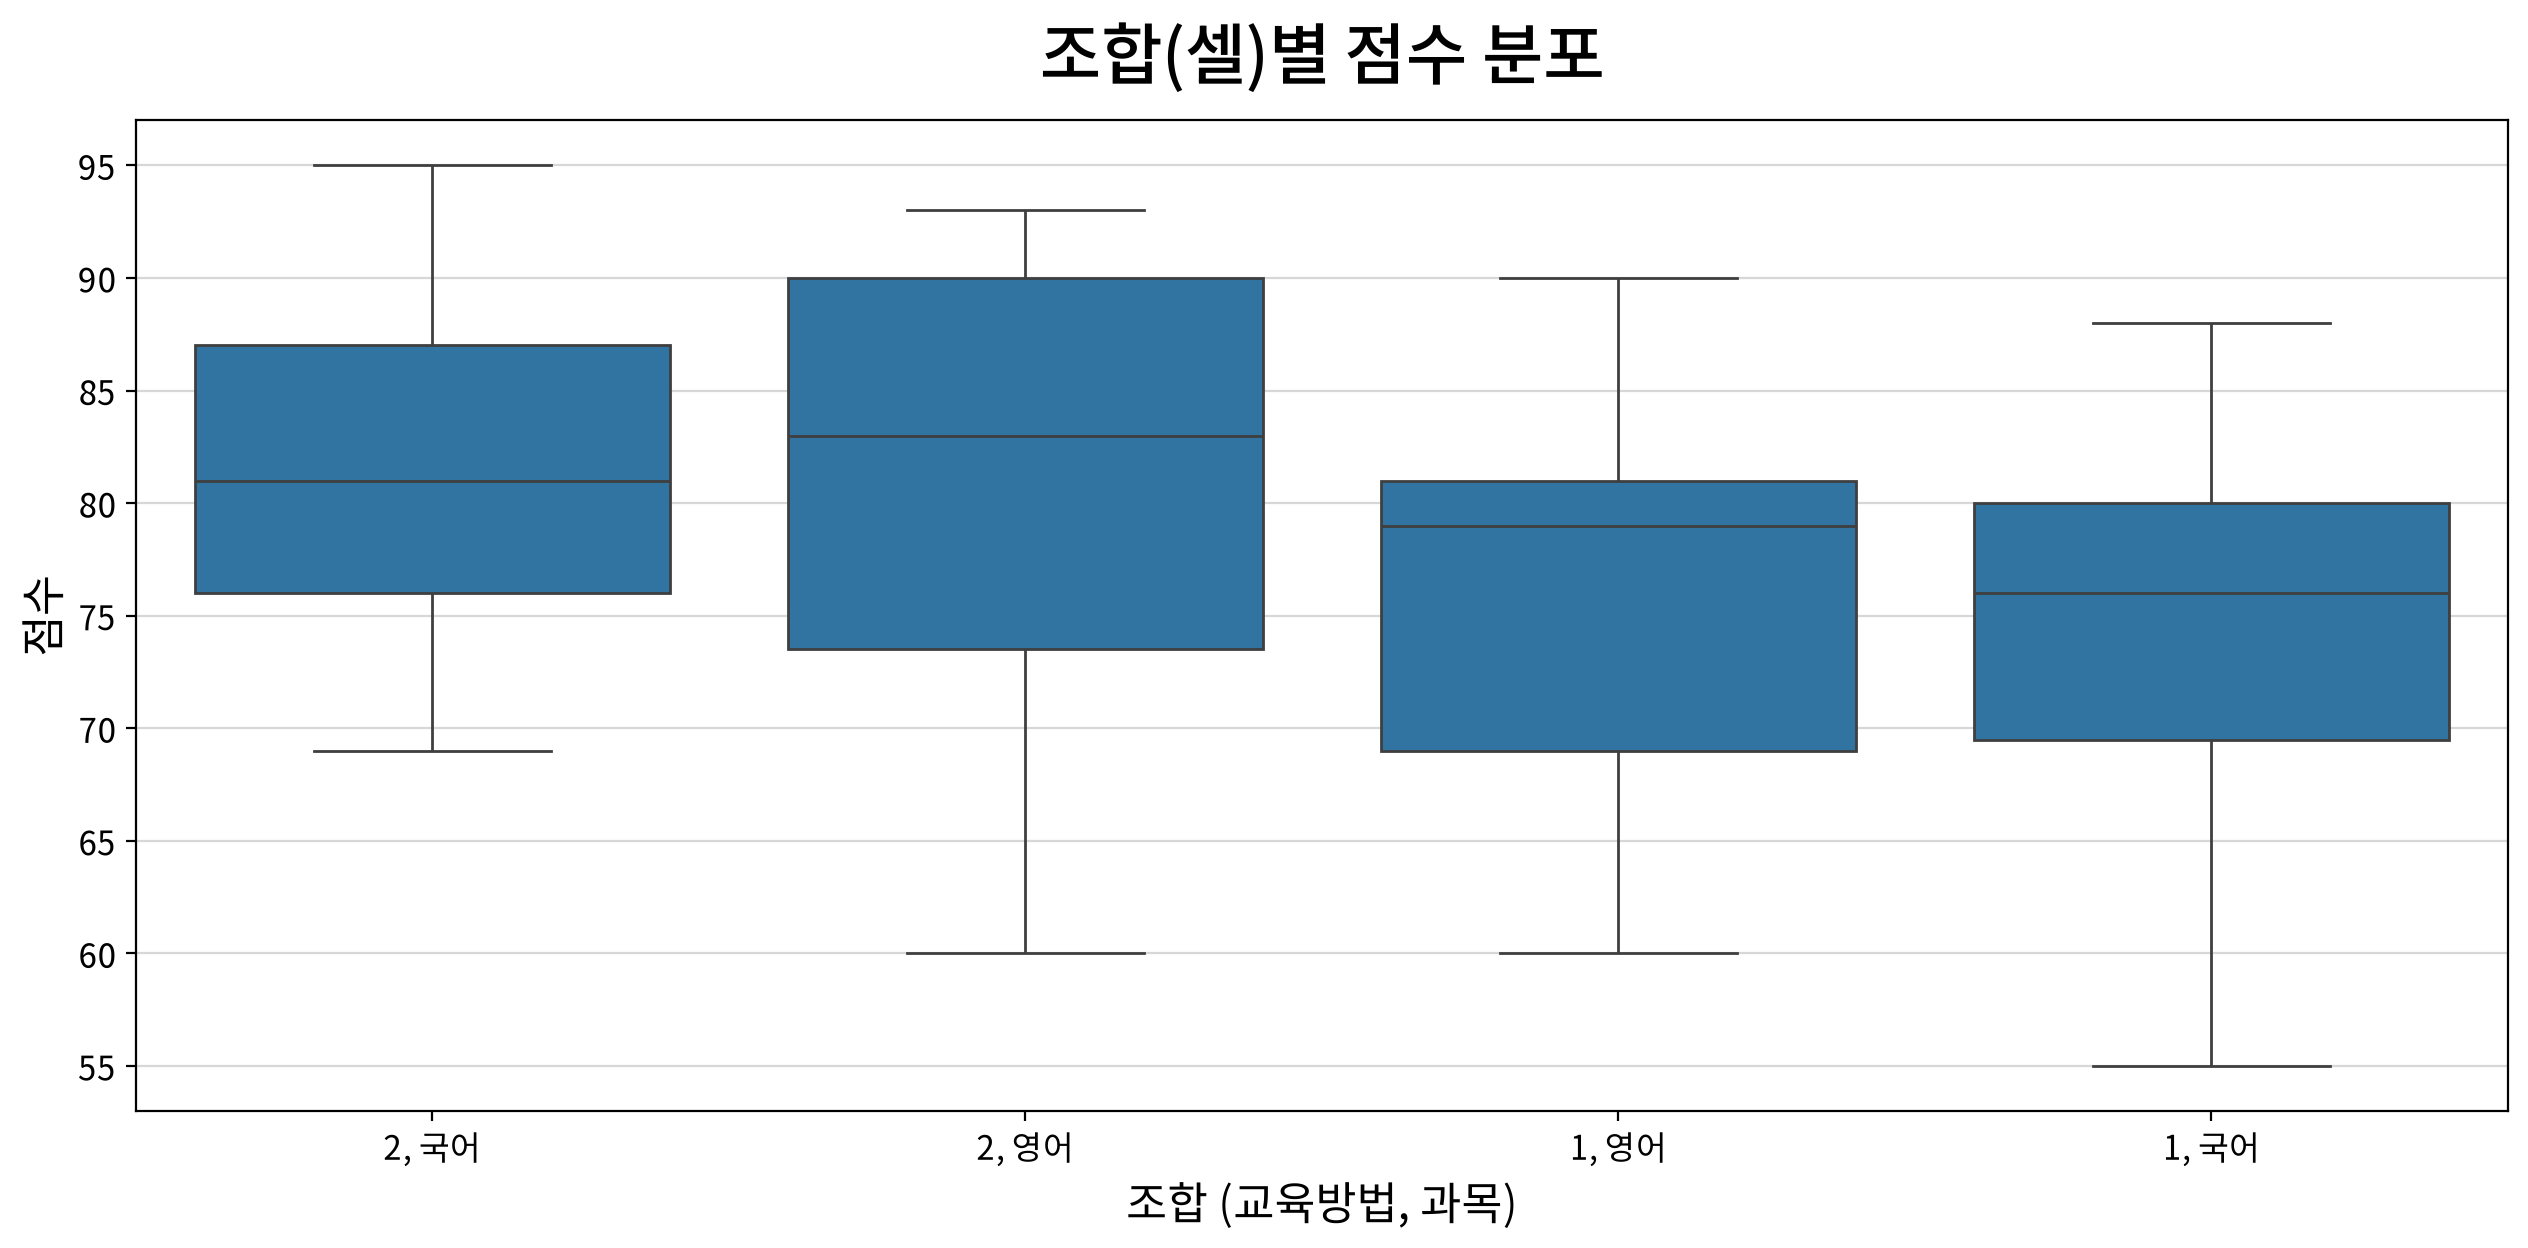

비교한 조합 쌍: 6개
유의한 쌍: 0개
평균 차이가 가장 큰 쌍: (1, 국어) vs (2, 국어) → 차이 6.818, 효과크기 Medium, p-value 0.356
평균 차이가 가장 작은 쌍: (2, 국어) vs (2, 영어) → 차이 1.000, 효과크기 Negligible, p-value 0.995

[1] 1쌍 중 유의한 쌍: 0개
(유의한 쌍 없음)

[2] 1쌍 중 유의한 쌍: 0개
(유의한 쌍 없음)


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,"1, 국어","1, 영어",74.545,75.818,-1.273,4.097,-0.311,0.989,-0.131,False,Negligible
1,Tukey HSD,"1, 국어","2, 국어",74.545,81.364,-6.818,4.097,-1.664,0.356,-0.740,False,Medium
2,Tukey HSD,"1, 국어","2, 영어",74.545,80.364,-5.818,4.097,-1.420,0.495,-0.530,False,Medium
3,Tukey HSD,"1, 영어","2, 국어",75.818,81.364,-5.545,4.097,-1.353,0.535,-0.624,False,Medium
4,Tukey HSD,"1, 영어","2, 영어",75.818,80.364,-4.545,4.097,-1.109,0.686,-0.425,False,Small
5,Tukey HSD,"2, 국어","2, 영어",81.364,80.364,1.000,4.097,0.244,0.995,0.098,False,Negligible


In [17]:
my_stats.posthoc_twoway(mdf1, y='점수', between=['교육방법', '과목'])

- 답변

1. 교장 선생님의 요구대로 네 개의 조합을 서로 짝지어 비교했습니다. 사후검정이 비교한 조합 쌍은 모두 몇 개인가요?
    - 6개
2. 교장 선생님이 지목한 것처럼, 평균 점수 차이가 가장 큰 쌍은 1번-국어와 2번-국어의 비교였습니다. 이 두 조합의 평균 차이는 몇 점인가요? (소수 셋째 자리, 부호 없이)
    - 6.818점
3. 그렇다면 이 6개의 쌍 중에서 유의수준 5%에서 통계적으로 유의한 차이를 보인 쌍은 몇 개인가요?
    - 0개
4. 유의한 쌍은 없었지만 효과크기까지 무시할 수준은 아니었습니다. 6개의 쌍 중 효과크기가 Medium으로 판정된 쌍은 몇 개인가요?
    - 3쌍
        - 1, 국어 / 2, 국어
        - 1, 국어 / 2, 영어	
        - 1, 영어 / 2, 국어
5. 교장 선생님이 콕 집어 물은 1번-국어 대 2번-국어 쌍은, 6쌍 중 평균 차이가 가장 크고 유의확률도 가장 작았습니다. 그 유의확률은 얼마인가요? (소수 셋째 자리)
    - 0.356

#### 문제 2 — 독성학연구소의 신입 연구원

- 당신은 독성학연구소의 신입 연구원입니다.
    - 지난 시간 poisons 데이터셋의 이원분산분석에서 독극물·해독제·둘의 상호작용이 유의하게 나왔고, 조합별 평균을 근거로 당신은 "단일 표준 해독제 대신 독극물별 맞춤 프로토콜(P1은 T2, P2·P3는 T4)"을 제안했습니다.
    - 평균이 조금 높다고 해독제를 바꾸려면 현장 교육을 다시 해야 합니다. 그 차이가 통계적으로 확실한 조합만 골라 주세요. P1에서 T2가 T1보다 정말 낫다고 말할 수 있습니까?
    - 12개 조합(독극물 × 해독제)을 서로 짝지어 비교하는 사후검정으로, 어느 조합 사이의 차이가 실제로 유의한지 확인하세요.

- 문제

1. 12개 조합을 서로 짝지어 비교했습니다. 사후검정이 비교한 조합 쌍은 모두 몇 개인가요?
2. 66개의 쌍 중에서 유의수준 5%에서 통계적으로 유의한 차이를 보인 쌍은 몇 개인가요?
3. 평균 생존시간의 차이가 가장 크게 벌어진 쌍은 (P1, T1)과 (P3, T4)의 비교였습니다. 이 두 조합의 평균 차이는 몇 시간인가요? (소수 셋째 자리, 부호 없이)
4. P1에 중독된 개체 안에서 해독제끼리 비교한 6개의 쌍 중, 유의한 차이를 보인 쌍은 몇 개인가요?
5. 반대로 P3에 중독된 개체 안에서 해독제끼리 비교한 6개의 쌍 중, 유의한 차이를 보인 쌍은 몇 개인가요?

In [18]:
df2 = load_data('poisons')
df2

📚 독극물 종류별로 동물의 생존시간을 기록한 실험 데이터 (출처: 방송통신대학교 통계학 개론)


,time,poison,treat
0,3.800,P1,T1
1,2.700,P1,T1
2,1.700,P1,T1
3,2.200,P1,T1
4,0.700,P1,T1
...,...,...,...
355,4.700,P3,T4
356,4.900,P3,T4
357,4.900,P3,T4
358,4.500,P3,T4


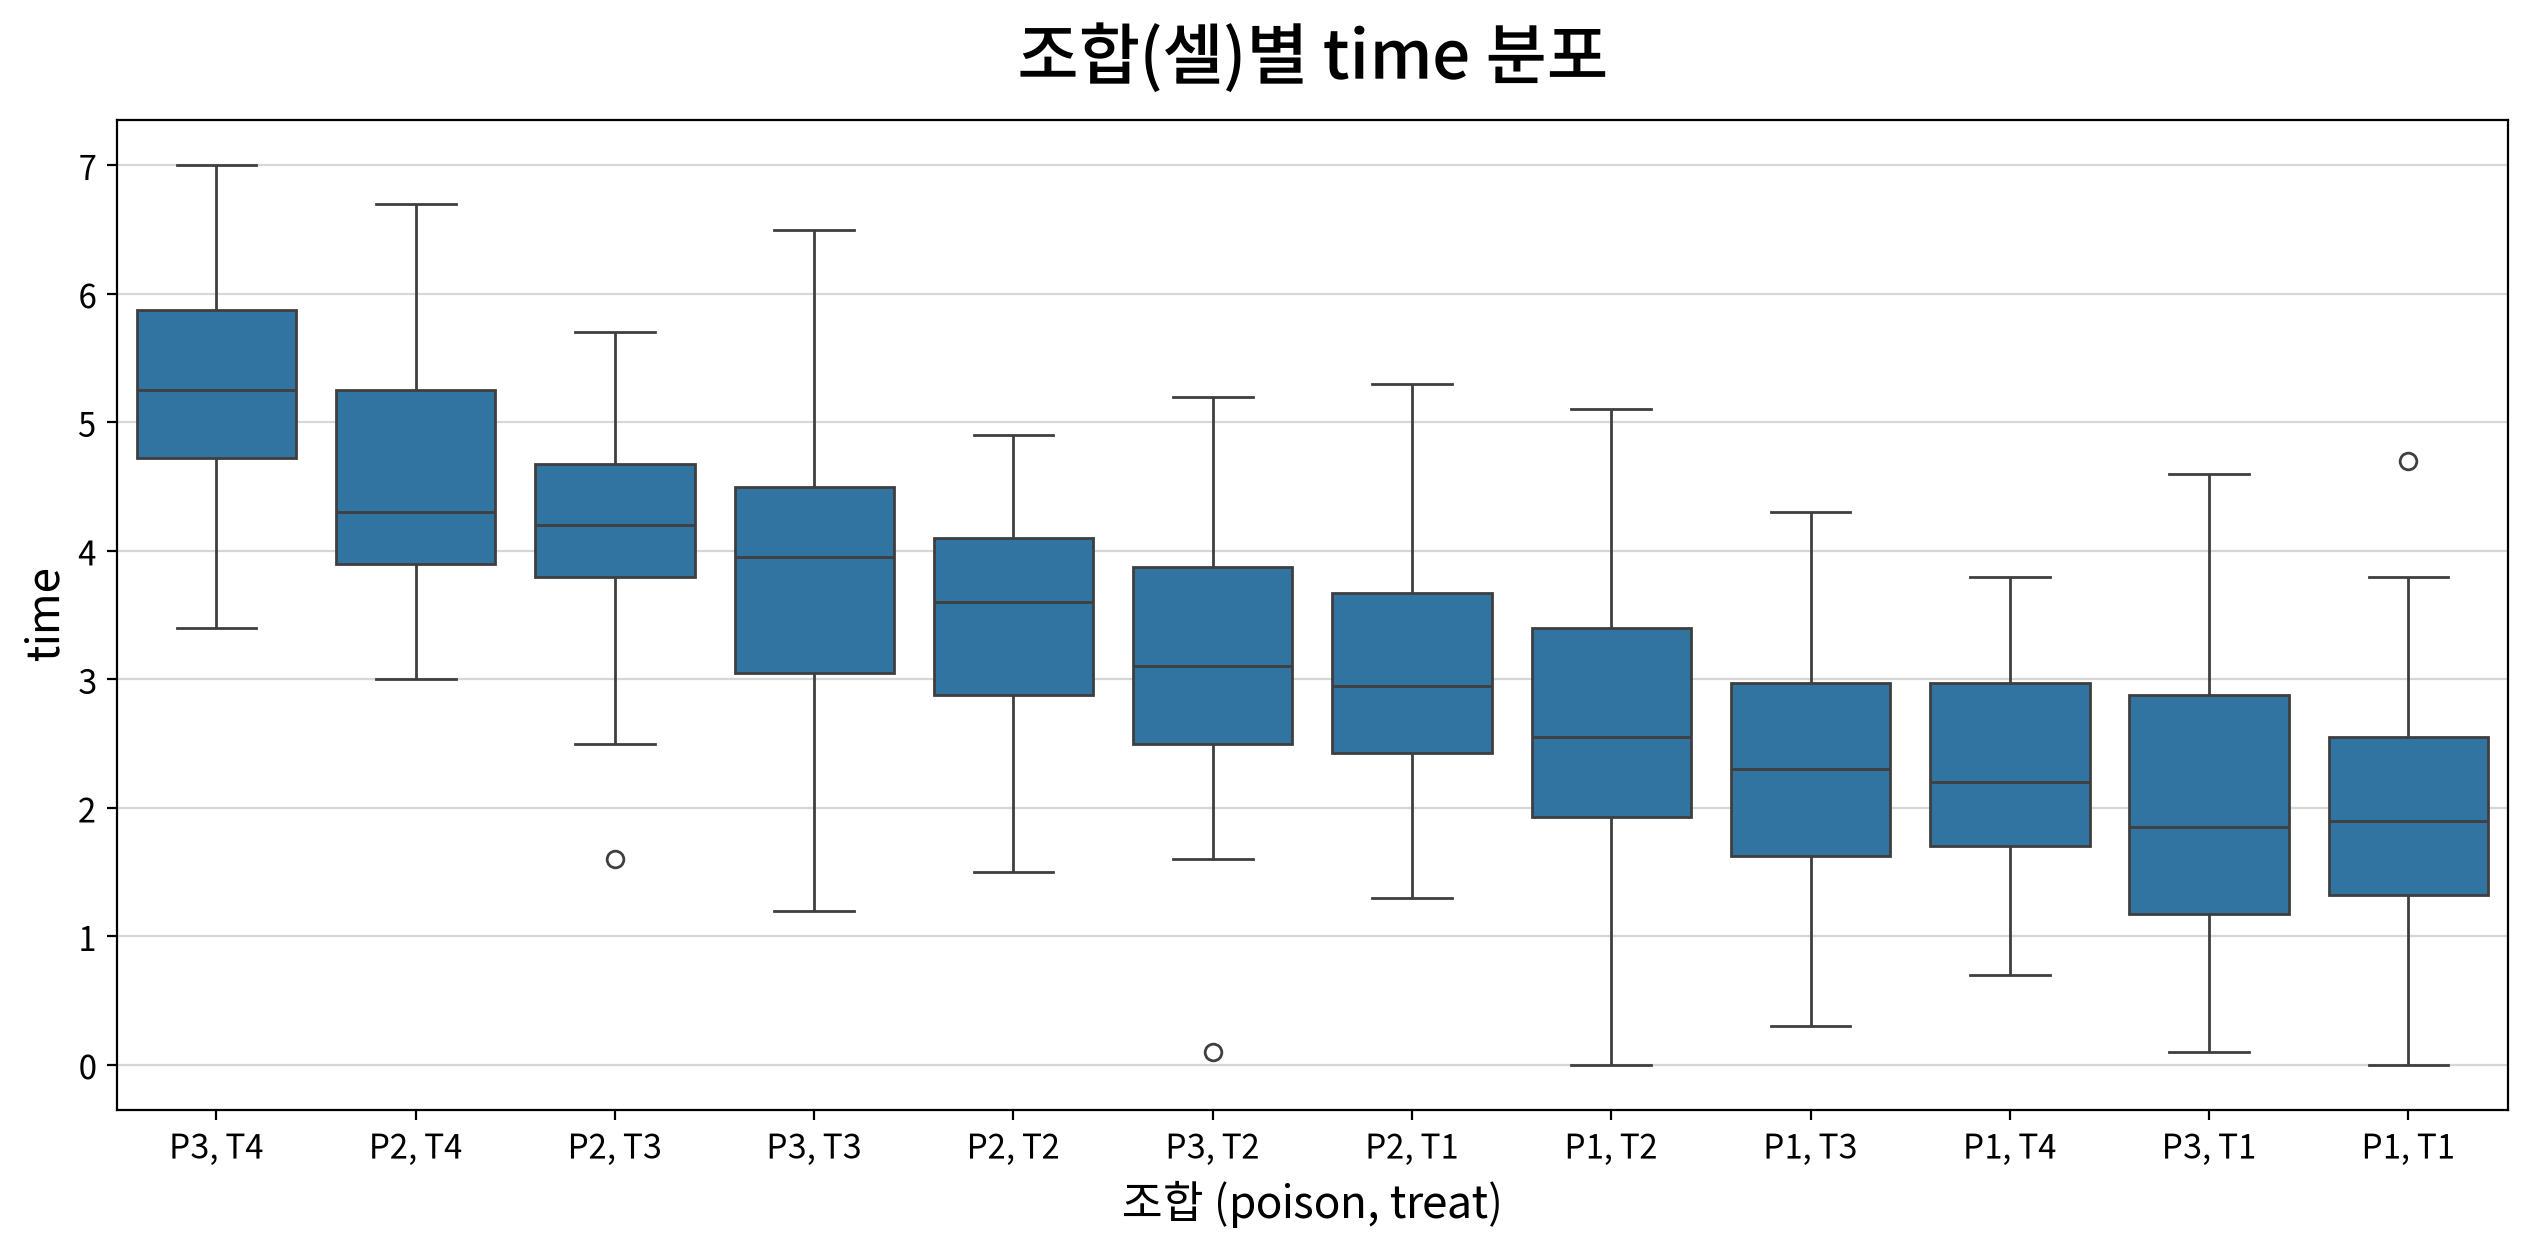

비교한 조합 쌍: 66개
유의한 쌍: 38개
평균 차이가 가장 큰 쌍: (P1, T1) vs (P3, T4) → 차이 3.307, 효과크기 Large, p-value 0.000
평균 차이가 가장 작은 쌍: (P2, T1) vs (P3, T2) → 차이 0.053, 효과크기 Negligible, p-value 1.000

[P1] 6쌍 중 유의한 쌍: 0개
(유의한 쌍 없음)

[P2] 6쌍 중 유의한 쌍: 3개
     A      B   diff  pval  significant
P2, T1 P2, T3 -1.073 0.002         True
P2, T1 P2, T4 -1.467 0.000         True
P2, T2 P2, T4 -1.103 0.001         True

[P3] 6쌍 중 유의한 쌍: 5개
     A      B   diff  pval  significant
P3, T1 P3, T2 -1.083 0.002         True
P3, T1 P3, T3 -1.710 0.000         True
P3, T1 P3, T4 -3.247 0.000         True
P3, T2 P3, T4 -2.163 0.000         True
P3, T3 P3, T4 -1.537 0.000         True


,test,A,B,mean_A,mean_B,diff,se,T,pval,hedges,significant,effect_size
0,Tukey HSD,"P1, T1","P1, T2",1.980,2.670,-0.690,0.258,-2.677,0.243,-0.649,False,Medium
1,Tukey HSD,"P1, T1","P1, T3",1.980,2.370,-0.390,0.258,-1.513,0.936,-0.402,False,Small
2,Tukey HSD,"P1, T1","P1, T4",1.980,2.280,-0.300,0.258,-1.164,0.991,-0.328,False,Small
3,Tukey HSD,"P1, T1","P2, T1",1.980,3.070,-1.090,0.258,-4.228,0.002,-1.056,True,Large
4,Tukey HSD,"P1, T1","P2, T2",1.980,3.433,-1.453,0.258,-5.638,0.000,-1.480,True,Large
5,Tukey HSD,"P1, T1","P2, T3",1.980,4.143,-2.163,0.258,-8.392,0.000,-2.203,True,Large
6,Tukey HSD,"P1, T1","P2, T4",1.980,4.537,-2.557,0.258,-9.917,0.000,-2.569,True,Large
7,Tukey HSD,"P1, T1","P3, T1",1.980,2.040,-0.060,0.258,-0.233,1.000,-0.057,False,Negligible
8,Tukey HSD,"P1, T1","P3, T2",1.980,3.123,-1.143,0.258,-4.435,0.001,-1.110,True,Large
9,Tukey HSD,"P1, T1","P3, T3",1.980,3.750,-1.770,0.258,-6.866,0.000,-1.583,True,Large


In [19]:
my_stats.posthoc_twoway(df2, y='time', between=['poison', 'treat'])

- 답변

1. 12개 조합을 서로 짝지어 비교했습니다. 사후검정이 비교한 조합 쌍은 모두 몇 개인가요?
    - 66쌍
2. 66개의 쌍 중에서 유의수준 5%에서 통계적으로 유의한 차이를 보인 쌍은 몇 개인가요?
    - 38개
3. 평균 생존시간의 차이가 가장 크게 벌어진 쌍은 (P1, T1)과 (P3, T4)의 비교였습니다. 이 두 조합의 평균 차이는 몇 시간인가요? (소수 셋째 자리, 부호 없이)
    - 3.307
4. P1에 중독된 개체 안에서 해독제끼리 비교한 6개의 쌍 중, 유의한 차이를 보인 쌍은 몇 개인가요?
    - 0개
5. 반대로 P3에 중독된 개체 안에서 해독제끼리 비교한 6개의 쌍 중, 유의한 차이를 보인 쌍은 몇 개인가요?
    - 5개